In [21]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from collections import Counter
from torch.utils.data import random_split, DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import time

# Task 1. Study and Prepare the Data

In [2]:
# Download and load CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True,transform=transforms.ToTensor())

test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True,transform=transforms.ToTensor())

100.0%


In [3]:
# Analyze the dataset
classes = train_dataset.classes

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Image dimensions:", train_dataset.data.shape[1:])
print("Number of classes:", len(classes))
print("Classes:", classes)

Training samples: 50000
Test samples: 10000
Image dimensions: (32, 32, 3)
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
# Inspect class distribution
class_counts = Counter(train_dataset.targets)

for i, class_name in enumerate(classes):
    print(f"{class_name}: {class_counts[i]}")

airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


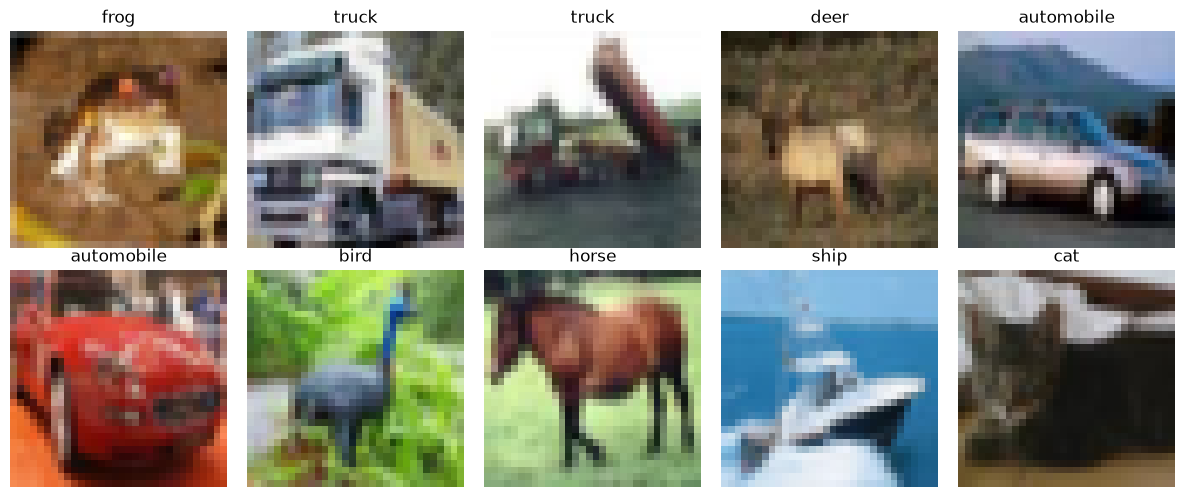

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = train_dataset.data[i]
    label = train_dataset.targets[i]

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Normalization
# Source: https://stackoverflow.com/questions/66678052/how-to-calculate-the-mean-and-the-std-of-cifar10-data
mean = [0.49139968, 0.48215827 ,0.44653124]
std =  [0.24703233, 0.24348505, 0.26158768]
train_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

In [8]:
# Create all 3 splits
seed = 587
rng = np.random.default_rng(seed)

train_subset, val_subset = random_split(
    train_dataset, [40000, 10000],
    generator=torch.Generator().manual_seed(seed)
)
 # Test already defined in the first cell

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_dataset))

Training: 40000
Validation: 10000
Test: 10000


In [10]:
# Data loaders for efficient batch processing
train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Task 2. Implement and Compare the Models


In [25]:
if torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")

In [26]:
# AlexNet
#width and depth can be changed more easily with this new implementation. extra_convs is depth
class AlexNet(nn.Module):
    
    def __init__(self, num_classes=10, width=1.0, extra_convs=0, dropout=0.5):
        super().__init__()
        c1, c2, c3, c4, c5 = [int(c * width) for c in (64, 192, 384, 256, 256)]
        h1, h2 = int(1024 * width), int(512 * width)
        layers = [
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c3, c4, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c4, c5, 3, padding=1), nn.ReLU(inplace=True),
        ]
        for _ in range(extra_convs):
            layers += [nn.Conv2d(c5, c5, 3, padding=1), nn.ReLU(inplace=True)]
        layers.append(nn.MaxPool2d(2, 2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c5 * 4 * 4, h1), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h2, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [27]:
# ResNet
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out += identity
        out = self.relu(out)

        return out

##width and depth can be changed more easily with this new implementation. Blocks is depth
class ResNet18(nn.Module):
    def __init__(self, num_classes=10, width=64, blocks=(2, 2, 2, 2), dropout=0.0):
        super().__init__()
        self.in_channels = width
        self.conv1 = nn.Conv2d(3, width, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(width)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(width, blocks[0], stride=1)
        self.layer2 = self.make_layer(width * 2, blocks[1], stride=2)
        self.layer3 = self.make_layer(width * 4, blocks[2], stride=2)
        self.layer4 = self.make_layer(width * 8, blocks[3], stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(width * 8, num_classes)

    def make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc(self.drop(x))

In [28]:
# Initiate models
alexnet = AlexNet().to(device)
resnet = ResNet18().to(device)

In [29]:
# Training configuration
criterion = nn.CrossEntropyLoss()

learning_rate = 0.001
epochs = 20

alexnet_optimizer = torch.optim.Adam(alexnet.parameters(), lr=learning_rate)
resnet_optimizer = torch.optim.Adam(resnet.parameters(), lr=learning_rate)

In [30]:
# Logic to train for a single epoch

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

    # Evaluate the model
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

"""
# old one
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)
    """




'\n# old one\ndef train_one_epoch(model, loader, optimizer):\n    model.train()\n    total_loss = 0\n    for images, labels in loader:\n        images, labels = images.to(device), labels.to(device)\n        optimizer.zero_grad()\n        outputs = model(images)\n        loss = criterion(outputs, labels)\n        loss.backward()\n        optimizer.step()\n        total_loss += loss.item()\n    return total_loss / len(loader)\n    '

In [31]:
# Training Loop
def train_model(model, optimizer, name):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_accuracy = 0
    start = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_accuracy = evaluate(model, val_loader)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_accuracy)
        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | "
            f"Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.4f}"
        )
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), f"{name}_best.pth")
            
    history['time'] = time.time() - start
    history['params'] = sum(p.numel() for p in model.parameters())
    print(f"{name} best val acc: {best_accuracy:.4f} | time: {history['time']:.0f}s | params: {history['params']:,}")
    return history

In [32]:
# Run Training
results = {}
results['alex_base'] = train_model(alexnet, alexnet_optimizer, "alexnet")
results['resnet_base'] = train_model(resnet, resnet_optimizer, "resnet")

alexnet | Epoch 1/20 | Train loss: 1.8373 | Train acc: 0.2989 | Val loss: 1.6103 | Val accuracy: 0.4290
alexnet | Epoch 2/20 | Train loss: 1.3934 | Train acc: 0.4885 | Val loss: 1.2592 | Val accuracy: 0.5568
alexnet | Epoch 3/20 | Train loss: 1.1812 | Train acc: 0.5744 | Val loss: 1.0590 | Val accuracy: 0.6254
alexnet | Epoch 4/20 | Train loss: 1.0284 | Train acc: 0.6346 | Val loss: 0.9622 | Val accuracy: 0.6651
alexnet | Epoch 5/20 | Train loss: 0.9111 | Train acc: 0.6824 | Val loss: 0.8791 | Val accuracy: 0.6987
alexnet | Epoch 6/20 | Train loss: 0.8222 | Train acc: 0.7131 | Val loss: 0.8912 | Val accuracy: 0.6870
alexnet | Epoch 7/20 | Train loss: 0.7297 | Train acc: 0.7461 | Val loss: 0.8352 | Val accuracy: 0.7133
alexnet | Epoch 8/20 | Train loss: 0.6469 | Train acc: 0.7730 | Val loss: 0.8206 | Val accuracy: 0.7197
alexnet | Epoch 9/20 | Train loss: 0.5753 | Train acc: 0.7989 | Val loss: 0.8361 | Val accuracy: 0.7305
alexnet | Epoch 10/20 | Train loss: 0.5038 | Train acc: 0.8238 |

In [33]:
# Test both models on their best validation checkpoints
for model, name in [(alexnet, "alexnet"), (resnet, "resnet")]:
    model.load_state_dict(torch.load(f"{name}_best.pth", map_location=device))

    test_loss, test_accuracy = evaluate(model, test_loader)

    print(
        f"{name}: Test loss = {test_loss:.4f}, "
        f"Test accuracy = {test_accuracy:.4f}"
    )

alexnet: Test loss = 0.9983, Test accuracy = 0.7391
resnet: Test loss = 0.9014, Test accuracy = 0.8229


In [38]:
#Helper Functions for plotting
def plot_metrics(history, title="Training Curves"):
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    
    # Loss plot
    ax1.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue')
    ax1.plot(epochs_range, history['val_loss'], label='Val Loss', color='red', linestyle='--')
    ax1.set_title(f"{title} - Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)
    
    # Accuracy plot
    ax2.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='blue')
    ax2.plot(epochs_range, history['val_acc'], label='Val Accuracy', color='red', linestyle='--')
    ax2.set_title(f"{title} - Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()



# Overlay plots of same metric
def plot_compare(histories, key='val_acc'):
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("Epochs"); plt.ylabel(key); plt.legend(); plt.grid(True); plt.show()

def pick(*names): return {n: results[n] for n in names}

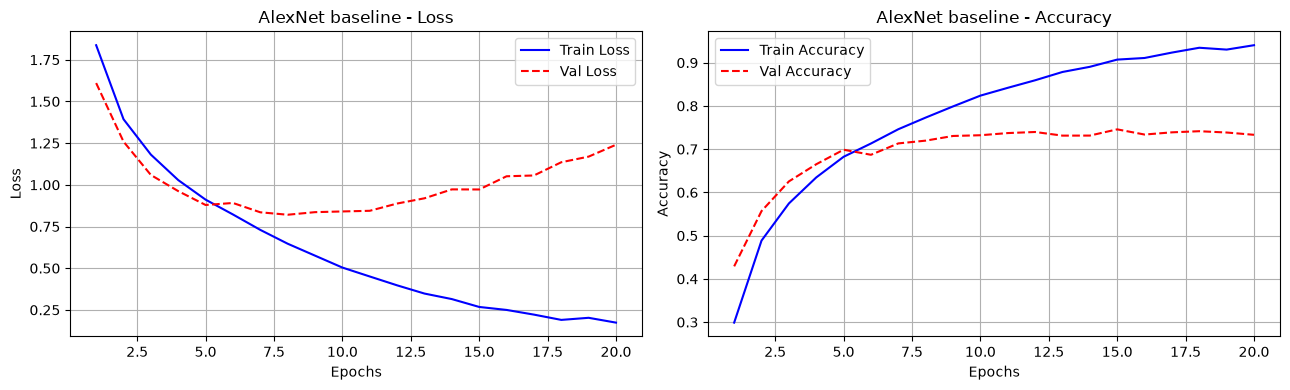

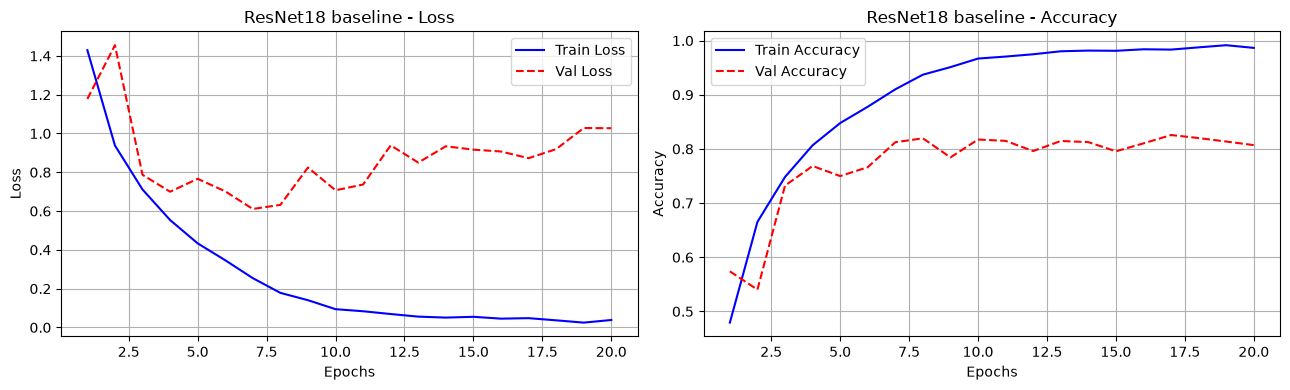

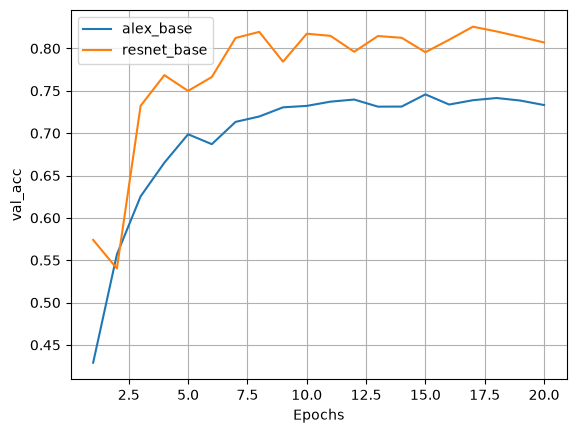

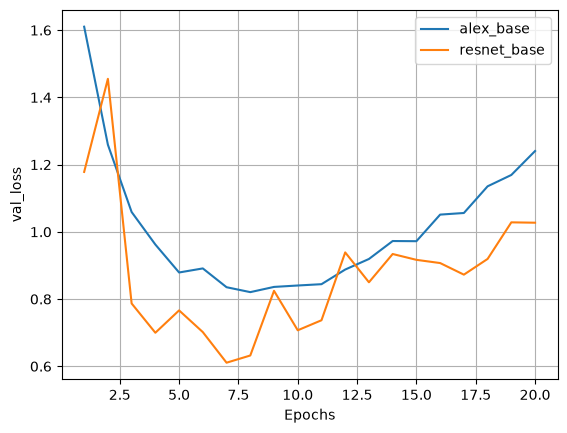

In [39]:
plot_metrics(results['alex_base'], "AlexNet baseline")
plot_metrics(results['resnet_base'], "ResNet18 baseline")

plot_compare(pick('alex_base', 'resnet_base'), 'val_acc')
plot_compare(pick('alex_base', 'resnet_base'), 'val_loss')

# Task 3 Investigate Capacity and Regularization